<a href="https://colab.research.google.com/github/PiyushAgrawal05/Phoneme-Recognition-Model/blob/main/Phoneme_Recognition_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Phase 1: Environment Setup & Authentication

### 1. Mount Google Drive
* **Purpose:** Mounts persistent cloud storage.
* **Operations:** Connects Google Drive to `/content/drive` to securely store and load `.pth` model checkpoints across session restarts without losing progress.

In [1]:
# cell 1
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 2. Dependency Installations & Authentication
* **Purpose:** Installs external libraries and authenticates the Hugging Face session.
* **Operations:**
  * Installs `datasets`, `torchaudio`, `jiwer`, `g2p_en`, and `gradio`.
  * Logs into the Hugging Face Hub via OAuth to allow streaming of gated datasets.

In [2]:
# Cell 2: Install Required Dependencies
!pip install -q datasets torchaudio huggingface_hub jiwer g2p_en gradio

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
# cell 3
from huggingface_hub import login
login()


### Cell 4: NLTK Tokenizer Resource Download
* **Purpose:** Downloads linguistic resources required by the G2P (Grapheme-to-Phoneme) engine.

In [4]:
# Cell 4: Download NLTK Support Packages
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('cmudict')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package cmudict to /root/nltk_data...
[nltk_data]   Unzipping corpora/cmudict.zip.


True

## Phase 2: Vocabulary & Data Ingestion Pipeline
### Cell 5: Vocabulary Definition & Label Normalization
* **Purpose:** Constructs the deterministic mapping between CMU ARPAbet phonemes and integer indices.
* **Operations:** Maps 39 phonemes, 1 `` token, and strictly reserves index `0` for the CTC `` token (Total classes: 41).

In [5]:
# Cell 5: Vocabulary Definition and Mapping
import re

cmu_phonemes = [
    "AA", "AE", "AH", "AO", "AW", "AY", "B", "CH", "D", "DH", "EH", "ER",
    "EY", "F", "G", "HH", "IH", "IY", "JH", "K", "L", "M", "N", "NG", "OW",
    "OY", "P", "R", "S", "SH", "T", "TH", "UH", "UW", "V", "W", "Y", "Z", "ZH",
    ""
]

vocab_dict = {"": 0}
for i, phn in enumerate(cmu_phonemes):
    vocab_dict[phn] = i + 1

id_to_vocab = {v: k for k, v in vocab_dict.items()}

def clean_phoneme(phn):
    phn = re.sub(r'\d+', '', phn).upper()
    return phn if phn in vocab_dict else ""

print(f"Vocabulary initialized with {len(vocab_dict)} classes (Blank index: {vocab_dict['']}).")

Vocabulary initialized with 40 classes (Blank index: 40).


### Cell 6: Dataset Streaming & Stratified Partitioning
* **Purpose:** Initializes memory-efficient audio data streams.
* **Operations:** Loads native LibriSpeech, non-native SpeechOcean762, and splits L2 Arctic into strict 80/10/10 Train-Validation-Test streams.

In [6]:
# Cell 6: Load and Split Streaming Datasets
from datasets import load_dataset

# 1. LibriSpeech (Native English Baseline)
libri_stream = load_dataset("openslr/librispeech_asr", "clean", split="train.100", streaming=True)

# 2. SpeechOcean762 (Non-Native Expansion)
so762_stream = load_dataset("mispeech/speechocean762", split="train", streaming=True)

# 3. L2 Arctic (Non-Native Target Domain - Split into Train, Validation, and Test)
# Load the full "scripted" dataset (fits easily in memory)
l2_dataset = load_dataset("KoelLabs/L2Arctic", split="scripted")

# Create a randomized 80% Train / 20% Temp split
l2_train_test = l2_dataset.train_test_split(test_size=0.2, seed=42)

# Split the 20% Temp into 10% Validation / 10% Test
l2_val_test = l2_train_test['test'].train_test_split(test_size=0.5, seed=42)

# Convert them back to streaming (IterableDataset) to match your pipeline's format
l2_train_stream = l2_train_test['train'].to_iterable_dataset()
l2_val_stream   = l2_val_test['train'].to_iterable_dataset()
l2_test_stream  = l2_val_test['test'].to_iterable_dataset()

# Quick diagnostic check
sample = next(iter(so762_stream))
print("Audio array shape:", sample["audio"]["array"].shape)
print("Sampling rate:", sample["audio"]["sampling_rate"])

README.md:   0%|          | 0.00/11.0k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/7.55k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.93k [00:00<?, ?B/s]

...

data/scripted-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  423MB            

data/scripted-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating spontaneous split:   0%|          | 0/22 [00:00<?, ? examples/s]

Generating scripted split:   0%|          | 0/3599 [00:00<?, ? examples/s]

Audio array shape: (41280,)
Sampling rate: 16000


In [7]:
# Grab one sample from each stream
libri_sample = next(iter(libri_stream))
so762_sample = next(iter(so762_stream))
l2_sample = next(iter(l2_train_stream))

print("LibriSpeech keys:", libri_sample.keys())
print("SpeechOcean keys:", so762_sample.keys())
print("L2 Arctic keys:", l2_sample.keys())

LibriSpeech keys: dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
SpeechOcean keys: dict_keys(['accuracy', 'completeness', 'fluency', 'prosodic', 'text', 'total', 'words', 'speaker', 'gender', 'age', 'audio'])
L2 Arctic keys: dict_keys(['audio', 'ipa', 'text', 'g2p', 'speaker_code', 'speaker_gender', 'speaker_native_language'])


### Cell 7: Audio Feature Extraction Pipeline
* **Purpose:** Transforms raw audio waveforms into training features.
* **Operations:** Extracts 80-channel Log-Mel Spectrograms at 16kHz with FP16 clamping (`min=1e-5`) to prevent gradient underflow.

In [8]:
# Cell 7: Feature Extraction Setup
import torch
import torchaudio

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=16000, n_mels=80, n_fft=400, hop_length=160
).to(device)
hop_length = mel_transform.hop_length

def extract_features(audio_array):
    tensor = torch.tensor(audio_array, dtype=torch.float32)
    if tensor.ndim == 1:
        tensor = tensor.unsqueeze(0)
    mel_spec = mel_transform(tensor.to(device))
    log_mel = torch.log(mel_spec.clamp(min=1e-5))
    return log_mel.squeeze(0).transpose(0, 1).cpu()

### Cell 8: Phonetic Transcription & Unified G2P Mapping
* **Purpose:** Standardizes phonetic targets across all datasets.
* **Operations:** Bypasses broken `g2p` dataset columns by dynamically converting raw English text transcripts into strict CMU ARPAbet phonemes.

In [9]:
# Cell 8: Target Processing and G2P Mapping
from g2p_en import G2p
g2p = G2p()

def process_libri(sample):
    raw_phones = g2p(sample["text"])
    labels = [vocab_dict[clean_phoneme(p)] for p in raw_phones if p.isalpha()]
    return {"raw_audio": sample["audio"]["array"], "labels": labels, "speaker": str(sample["speaker_id"])}

def process_so762(sample):
    raw_phones = [phone for word in sample["words"] for phone in word["phones"]]
    labels = [vocab_dict[clean_phoneme(p)] for p in raw_phones]
    return {"raw_audio": sample["audio"]["array"], "labels": labels, "speaker": str(sample["speaker"])}

def process_l2(sample):
    raw_phones = g2p(sample["text"])
    labels = [vocab_dict[clean_phoneme(p)] for p in raw_phones if p.isalpha()]
    return {"raw_audio": sample["audio"]["array"], "labels": labels, "speaker": str(sample["speaker_code"])}

libri_ready = libri_stream.map(process_libri, remove_columns=['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
so762_ready = so762_stream.map(process_so762, remove_columns=['accuracy', 'completeness', 'fluency', 'prosodic', 'text', 'total', 'words', 'speaker', 'gender', 'age', 'audio'])
l2_train_ready = l2_train_stream.map(process_l2, remove_columns=['audio', 'ipa', 'text', 'g2p', 'speaker_code', 'speaker_gender', 'speaker_native_language'])
l2_val_ready   = l2_val_stream.map(process_l2, remove_columns=['audio', 'ipa', 'text', 'g2p', 'speaker_code', 'speaker_gender', 'speaker_native_language'])
l2_test_ready  = l2_test_stream.map(process_l2, remove_columns=['audio', 'ipa', 'text', 'g2p', 'speaker_code', 'speaker_gender', 'speaker_native_language'])

print("Unified G2P preprocessing pipelines configured.")

Unified G2P preprocessing pipelines configured.


### Cell 9: Dynamic Batch Collation
* **Purpose:** Handles variable-length sequence batching for PyTorch's CTC loss.
* **Operations:** Zero-pads audio and target sequences to the maximum length in the mini-batch while retaining their true unpadded lengths.

In [10]:
# Cell 9: Collate Function for Variable Sequence Lengths
import numpy as np
from torch.nn.utils.rnn import pad_sequence

def ctc_collate_fn(batch):
    features_list = []
    labels_list = []
    input_lengths = []
    target_lengths = []

    for sample in batch:
        feat_tensor = torch.from_numpy(np.array(sample["raw_audio"], dtype=np.float32))
        features_list.append(feat_tensor)
        input_lengths.append(feat_tensor.shape[0])

        lbl_tensor = torch.tensor(sample["labels"], dtype=torch.long)
        labels_list.append(lbl_tensor)
        target_lengths.append(len(lbl_tensor))

    padded_features = pad_sequence(features_list, batch_first=True, padding_value=0.0)
    padded_labels = pad_sequence(labels_list, batch_first=True, padding_value=0)

    input_lengths = torch.tensor(input_lengths, dtype=torch.long)
    target_lengths = torch.tensor(target_lengths, dtype=torch.long)

    return padded_features, padded_labels, input_lengths, target_lengths

### Cell 10: Stream Filtering & DataLoader Initialization
* **Purpose:** Generates the final PyTorch DataLoaders.
* **Operations:** Discards empty or oversized audio clips (failsafe) and interleaves datasets for Stage 1 pre-training.

In [11]:
# Cell 10: Stream Filtering and DataLoader Construction
from datasets import interleave_datasets
from torch.utils.data import DataLoader

MAX_SAMPLES = 160000

def filter_length(sample):
    return len(sample["raw_audio"]) <= MAX_SAMPLES and len(sample["labels"]) > 0

l2_train_filtered = l2_train_ready.filter(filter_length)
l2_val_filtered   = l2_val_ready.filter(filter_length)
l2_test_filtered  = l2_test_ready.filter(filter_length)
libri_filtered    = libri_ready.filter(filter_length)
so762_filtered    = so762_ready.filter(filter_length)

pretrain_stream = interleave_datasets([libri_filtered, so762_filtered]).shuffle(seed=42, buffer_size=1000)
l2_train_stream_shuffled = l2_train_filtered.shuffle(seed=42, buffer_size=1000)

batch_size = 4
pretrain_loader = DataLoader(pretrain_stream, batch_size=batch_size, collate_fn=ctc_collate_fn)
finetune_loader = DataLoader(l2_train_stream_shuffled, batch_size=batch_size, collate_fn=ctc_collate_fn)
val_loader      = DataLoader(l2_val_filtered, batch_size=batch_size, collate_fn=ctc_collate_fn)
test_loader     = DataLoader(l2_test_filtered, batch_size=batch_size, collate_fn=ctc_collate_fn)

print("DataLoaders compiled with input-length validation.")

DataLoaders compiled with input-length validation.


## Phase 3: Model Architecture & Regularization
### Cell 11: Pure-Acoustic Conformer-CTC Architecture
* **Purpose:** Implements the core 12-layer Conformer neural network.
* **Operations:** Projects 80-dim audio features into a 256-dim model space, processing them through self-attention and outputting 41-class logits.

In [12]:
# Cell 11: 12-Layer Conformer CTC Model Definition
import torch.nn as nn
from torchaudio.models import Conformer

class PureAcousticConformer(nn.Module):
    def __init__(self, input_dim=80, d_model=256, num_classes=41):
        super().__init__()
        self.input_projection = nn.Linear(input_dim, d_model)
        self.conformer = Conformer(
            input_dim=d_model,
            num_heads=4,
            ffn_dim=1024,
            num_layers=12,
            depthwise_conv_kernel_size=31,
            dropout=0.1
        )
        self.classification_head = nn.Linear(d_model, num_classes)

    def forward(self, x, lengths):
        x = self.input_projection(x)
        x, _ = self.conformer(x, lengths)
        logits = self.classification_head(x)
        return logits.transpose(0, 1)

### Cell 12: SpecAugment Regularization Module
* **Purpose:** Artificially corrupts audio features to prevent overfitting.
* **Operations:** Randomly masks chunks of frequency bins and time steps during training.

In [13]:
# Cell 12: SpecAugment Implementation
class SpecAugment(nn.Module):
    def __init__(self):
        super().__init__()
        self.freq_mask = torchaudio.transforms.FrequencyMasking(freq_mask_param=27)
        self.time_mask = torchaudio.transforms.TimeMasking(time_mask_param=40)

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.freq_mask(x)
        x = self.time_mask(x)
        return x.transpose(1, 2)

In [14]:
import torch
import gc

# Force garbage collection and empty CUDA cache
gc.collect()
torch.cuda.empty_cache()
print("GPU Memory Cleared!")

GPU Memory Cleared!


### Cell 13: Model Initialization & Forward Pass Test
* **Purpose:** Pushes the model to the GPU and verifies tensor math.
* **Operations:** Runs a dummy input through the network to ensure the output shape perfectly matches `(Time, Batch, 41)`.

In [15]:
# Cell 13: Verification of Model Dimensions
model = PureAcousticConformer(input_dim=80, d_model=256, num_classes=41).to(device)
augmenter = SpecAugment().to(device)

dummy_input = torch.randn(2, 500, 80).to(device)
dummy_lengths = torch.tensor([500, 400]).to(device)

with torch.no_grad():
    dummy_output = model(augmenter(dummy_input), dummy_lengths)

print(f"Device: {device}")
print(f"Verified Model Output Shape (T, B, C): {dummy_output.shape}")
assert dummy_output.shape == (500, 2, 41), "Shape mismatch detected!"

Device: cuda
Verified Model Output Shape (T, B, C): torch.Size([500, 2, 41])


## Phase 4: Curriculum Learning Stage 1 (Baseline Pre-Training)
### Cell 14: Optimizer, Scheduler & Scaler Setup (Stage 1)
* **Purpose:** Configures optimization mechanics for heavy pre-training.
* **Operations:** Initializes CTC Loss (`blank=0`), AdamW optimizer, OneCycleLR scheduler, and FP16 GradScaler.

In [16]:
# Cell 14: Stage 1 Optimization Hyperparameters
import torch.optim as optim

criterion = nn.CTCLoss(blank=0, zero_infinity=True)
pretrain_steps = 20000
pretrain_lr = 5e-4

optimizer = optim.AdamW(model.parameters(), lr=pretrain_lr, weight_decay=1e-4)
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=pretrain_lr, total_steps=pretrain_steps, pct_start=0.1
)
scaler = torch.amp.GradScaler('cuda')

print("Stage 1 execution hyperparameters initialized.")

Stage 1 execution hyperparameters initialized.


### Cell 15: Stage 1 Pre-Training Loop (20,000 Steps)
* **Purpose:** Teaches the model generalized English acoustics from scratch.
* **Operations:** Minimizes CTC loss over 20,000 steps on LibriSpeech and SO762, then saves the baseline weights to Google Drive.

In [ ]:
# Cell 15: Stage 1 Training Execution Loop
import torch.nn.functional as F

model.train()
augmenter.train()

print(f"Starting Stage 1 Full Pre-training ({pretrain_steps} Steps)...")
global_step = 0
running_loss = 0.0

while global_step < pretrain_steps:
    for batch in pretrain_loader:
        if global_step >= pretrain_steps:
            break

        features, labels_2d, input_lengths, target_lengths = [b.to(device) for b in batch]
        frame_lengths = torch.div(input_lengths.view(-1), hop_length, rounding_mode='floor') + 1
        target_lengths = target_lengths.view(-1)

        valid_idx = frame_lengths >= target_lengths
        if not valid_idx.any():
            continue

        features = features[valid_idx]
        labels_2d = labels_2d[valid_idx]
        frame_lengths = frame_lengths[valid_idx]
        target_lengths = target_lengths[valid_idx]

        targets_1d = torch.cat([labels_2d[i, :target_lengths[i]] for i in range(labels_2d.shape[0])])
        if targets_1d.numel() == 0:
            continue

        optimizer.zero_grad()

        with torch.amp.autocast('cuda'):
            mel_specs = mel_transform(features)
            log_mels = torch.log(mel_specs.clamp(min=1e-5)).transpose(1, 2)
            logits = model(augmenter(log_mels), frame_lengths)
            log_probs = F.log_softmax(logits, dim=2, dtype=torch.float32)
            loss = criterion(log_probs, targets_1d, frame_lengths, target_lengths)

        if torch.isnan(loss) or torch.isinf(loss) or loss.item() <= 0.0:
            continue

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)

        scale_before = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        scale_after = scaler.get_scale()

        if scale_before <= scale_after:
            scheduler.step()

        running_loss += loss.item()
        global_step += 1

        if global_step % 200 == 0:
            avg_loss = running_loss / 200
            current_lr = scheduler.get_last_lr()[0]
            print(f"Step [{global_step}/{pretrain_steps}] | Loss: {avg_loss:.4f} | LR: {current_lr:.6f}")
            running_loss = 0.0

torch.save(model.state_dict(), '/content/drive/MyDrive/conformer_stage1_full.pth')
print("Stage 1 weights saved successfully to Google Drive!")

## Phase 5: Decoding, Evaluation & Diagnostics
### Cell 16: CTC Greedy Decoder Implementation
* **Purpose:** Converts raw network probabilities into readable text.
* **Operations:** Selects the highest probability per frame, collapses repeated tokens, and strips the CTC `` tokens to output phoneme strings.

In [17]:
# Cell 16: CTC Greedy Decoding Function
def ctc_greedy_decode(logits, input_lengths):
    logits = logits.transpose(0, 1)
    predictions = torch.argmax(logits, dim=-1).cpu().numpy()

    decoded_sequences = []
    for i in range(predictions.shape[0]):
        pred = predictions[i][:int(input_lengths[i])]
        collapsed = []
        prev_token = -1
        for token in pred:
            if token != prev_token:
                phoneme = id_to_vocab.get(token, "")
                if token != 0 and phoneme != "" and phoneme != "":
                    collapsed.append(phoneme)
                prev_token = token
        decoded_sequences.append(" ".join(collapsed))
    return decoded_sequences

print("Greedy CTC decoding module compiled.")

Greedy CTC decoding module compiled.


### Cell 17: Alignment & Blank Distribution Inspector
* **Purpose:** Runs a diagnostic sanity check on the tensors.
* **Operations:** Verifies that the model correctly assigns the `` token to the vast majority of silent audio frames.

In [21]:
# Cell 17: Diagnostic Validation Batch Inspector
model.eval()

with torch.no_grad():
    for batch in val_loader:
        features, labels_2d, input_lengths, target_lengths = [b.to(device) for b in batch]
        with torch.amp.autocast('cuda'):
            mel_specs = mel_transform(features)
            log_mels = torch.log(mel_specs.clamp(min=1e-5)).transpose(1, 2)
            eval_frame_lengths = torch.div(input_lengths.view(-1), hop_length, rounding_mode='floor') + 1
            logits = model(log_mels, eval_frame_lengths)

        preds = torch.argmax(logits[:, 0, :], dim=-1).cpu().numpy()
        targets = labels_2d[0][:target_lengths[0]].cpu().numpy()

        print(f"Logits Tensor Shape: {logits.shape}")
        print(f"Raw Target IDs: {targets}")
        print(f"Phonetic Target: {[id_to_vocab.get(t, '') for t in targets]}")
        print(f"Raw Prediction Sequence (First 40 Frames): {preds[:40]}")
        actual_frames = int(eval_frame_lengths[0].item())
        print(f"Blank Allocation: {(preds[:actual_frames] == 0).sum()} / {actual_frames} frames")
        break

Logits Tensor Shape: torch.Size([524, 4, 41])
Raw Target IDs: [ 7 31 16 22 35 28 36 28 36 10 35  9 23 29 38 35 21 15 39 23  9 35 19]
Phonetic Target: ['B', 'T', 'HH', 'M', 'V', 'R', 'W', 'R', 'W', 'DH', 'V', 'D', 'N', 'S', 'Z', 'V', 'L', 'G', 'ZH', 'N', 'D', 'V', 'JH']
Raw Prediction Sequence (First 40 Frames): [39 39 39 39 39 39 39 39 39 39 39 11 39 39 39 39 39 39 39 39 11 17 17 11
 13 13 11 17 13 13 11 22 39 39 39 39 39 39 39 39]
Blank Allocation: 7 / 432 frames


### Cell 18: Quantitative Evaluation Function
* **Purpose:** Computes official error metrics.
* **Operations:** Generates predictions for an unseen dataset and uses `jiwer` to calculate the Phoneme Error Rate (PER), Substitution, Deletion, and Insertion rates.

In [22]:
# Reload the pristine Stage 1 weights
model.load_state_dict(torch.load('/content/drive/MyDrive/conformer_stage1_full.pth', map_location=device))
print("Baseline Stage 1 weights loaded for Ablation Study.")

Baseline Stage 1 weights loaded for Ablation Study.


In [23]:
# Cell 18: Complete Quantitative Evaluation Loop
import jiwer

def evaluate_loader(loader, active_model, split_name="Validation"):
    active_model.eval()
    print(f"\nEvaluating acoustic performance on {split_name} Set...")

    all_preds = []
    all_refs = []

    with torch.no_grad():
        for batch in loader:
            features, labels_2d, input_lengths, target_lengths = [b.to(device) for b in batch]
            labels_cpu = labels_2d.cpu().numpy()

            with torch.amp.autocast('cuda'):
                mel_specs = mel_transform(features)
                log_mels = torch.log(mel_specs.clamp(min=1e-5)).transpose(1, 2)
                eval_frame_lengths = torch.div(input_lengths.view(-1), hop_length, rounding_mode='floor') + 1
                logits = active_model(log_mels, eval_frame_lengths)

            preds = ctc_greedy_decode(logits, eval_frame_lengths.cpu().numpy())

            for i in range(labels_cpu.shape[0]):
                ref_tokens = labels_cpu[i][:target_lengths[i]]
                clean_tokens = [id_to_vocab.get(t, "") for t in ref_tokens if t != 0 and id_to_vocab.get(t, "") not in ["", ""]]
                if len(clean_tokens) > 0:
                    all_refs.append(" ".join(clean_tokens))
                    all_preds.append(preds[i])

            if len(all_refs) >= 50:
                break

    if len(all_refs) > 0:
        out = jiwer.process_words(all_refs, all_preds)
        total_phonemes = out.substitutions + out.deletions + out.hits
        print("-" * 42)
        print(f"Phoneme Error Rate (PER) : {out.wer * 100:.2f}%")
        print(f"Substitution Rate        : {(out.substitutions / total_phonemes) * 100:.2f}%")
        print(f"Deletion Rate            : {(out.deletions / total_phonemes) * 100:.2f}%")
        print(f"Insertion Rate           : {(out.insertions / total_phonemes) * 100:.2f}%")
        print("-" * 42)
        print(f"Target : '{all_refs[0]}'")
        print(f"Predict: '{all_preds[0]}'\n")
    return out.wer * 100

# Run evaluation on Stage 1 Baseline
evaluate_loader(val_loader, model, "L2 Arctic Validation (Stage 1)")
evaluate_loader(test_loader, model, "Unseen L2 Arctic TEST Split")


Evaluating acoustic performance on L2 Arctic Validation (Stage 1) Set...
------------------------------------------
Phoneme Error Rate (PER) : 42.07%
Substitution Rate        : 25.71%
Deletion Rate            : 12.12%
Insertion Rate           : 4.24%
------------------------------------------
Target : 'B T HH M V R W R W DH V D N S Z V L G ZH N D V JH'
Predict: 'B T HH M V W R W DH V D N S Z V L K SH N B T JH'


Evaluating acoustic performance on Unseen L2 Arctic TEST Split Set...
------------------------------------------
Phoneme Error Rate (PER) : 42.11%
Substitution Rate        : 24.88%
Deletion Rate            : 12.73%
Insertion Rate           : 4.50%
------------------------------------------
Target : 'F R DH T W N T TH T M DH T V N NG DH T M N SH K HH N D Z'
Predict: 'F R DH K W N T F T M DH T V N N D T T M N SH K HH N Z'



42.10526315789473

## Phase 6: Target Domain Adaptation (Stage 2)
### Cell 19: Fine-Tuning Optimizer & Scheduler Setup
* **Purpose:** Configures optimization for delicate domain adaptation.
* **Operations:** Drops the learning rate by 10x (`5e-5`) to protect generalized knowledge while adapting to new accents.

In [24]:
# Cell 19: Stage 2 Optimizer and Scheduler Setup
fine_tune_lr = 5e-5
finetune_steps = 5000

optimizer = optim.AdamW(model.parameters(), lr=fine_tune_lr, weight_decay=1e-4)
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=fine_tune_lr, total_steps=finetune_steps, pct_start=0.1
)
scaler = torch.amp.GradScaler('cuda')

print("Stage 2 optimization hyperparameters initialized.")

Stage 2 optimization hyperparameters initialized.


### Cell 20: Stage 2 Domain Adaptation Training Loop
* **Purpose:** Adapts the acoustic weights strictly to non-native L2 Arctic accents.
* **Operations:** Executes a targeted 5,000-step training loop to shift phoneme boundaries, saving the final weights to Google Drive.

In [ ]:
# Cell 20: Stage 2 Domain Adaptation Loop
model.train()
augmenter.train()

print(f"Starting Stage 2 Domain Adaptation ({finetune_steps} Steps)...")
global_step = 0
running_loss = 0.0

while global_step < finetune_steps:
    for batch in finetune_loader:
        if global_step >= finetune_steps:
            break

        features, labels_2d, input_lengths, target_lengths = [b.to(device) for b in batch]
        frame_lengths = torch.div(input_lengths.view(-1), hop_length, rounding_mode='floor') + 1
        target_lengths = target_lengths.view(-1)

        valid_idx = frame_lengths >= target_lengths
        if not valid_idx.any():
            continue

        features = features[valid_idx]
        labels_2d = labels_2d[valid_idx]
        frame_lengths = frame_lengths[valid_idx]
        target_lengths = target_lengths[valid_idx]

        targets_1d = torch.cat([labels_2d[i, :target_lengths[i]] for i in range(labels_2d.shape[0])])
        if targets_1d.numel() == 0:
            continue

        optimizer.zero_grad()

        with torch.amp.autocast('cuda'):
            mel_specs = mel_transform(features)
            log_mels = torch.log(mel_specs.clamp(min=1e-5)).transpose(1, 2)
            logits = model(augmenter(log_mels), frame_lengths)
            log_probs = F.log_softmax(logits, dim=2, dtype=torch.float32)
            loss = criterion(log_probs, targets_1d, frame_lengths, target_lengths)

        if torch.isnan(loss) or torch.isinf(loss) or loss.item() <= 0.0:
            continue

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)

        scale_before = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        scale_after = scaler.get_scale()

        if scale_before <= scale_after:
            scheduler.step()

        running_loss += loss.item()
        global_step += 1

        if global_step % 200 == 0:
            avg_loss = running_loss / 200
            current_lr = scheduler.get_last_lr()[0]
            print(f"Fine-tune Step [{global_step}/{finetune_steps}] | Loss: {avg_loss:.4f} | LR: {current_lr:.6f}")
            running_loss = 0.0

torch.save(model.state_dict(), '/content/drive/MyDrive/conformer_stage2_finetuned.pth')
print("Stage 2 Domain-Adapted weights saved to Google Drive!")

### Cell 21: Post-Adaptation Benchmark Run
* **Purpose:** Calculates the final accuracy of the completed pipeline.
* **Operations:** Evaluates the fine-tuned Stage 2 weights on the validation and unseen test sets.

In [25]:
# Reload the pristine Stage 2 weights
model.load_state_dict(torch.load('/content/drive/MyDrive/conformer_stage2_finetuned.pth', map_location=device))
print("Baseline Stage 2 weights loaded for Ablation Study.")

Baseline Stage 2 weights loaded for Ablation Study.


In [26]:
# Cell 21: Evaluate Stage 2 on Validation and Unseen Test Splits
evaluate_loader(val_loader, model, "L2 Arctic Validation (Stage 2 Adapted)")
evaluate_loader(test_loader, model, "Unseen L2 Arctic TEST Split")


Evaluating acoustic performance on L2 Arctic Validation (Stage 2 Adapted) Set...
------------------------------------------
Phoneme Error Rate (PER) : 32.41%
Substitution Rate        : 17.14%
Deletion Rate            : 12.91%
Insertion Rate           : 2.36%
------------------------------------------
Target : 'B T HH M V R W R W DH V D N S Z V L G ZH N D V JH'
Predict: 'B TH HH NG V W R W DH V D N S Z V L K SH N B L JH'


Evaluating acoustic performance on Unseen L2 Arctic TEST Split Set...
------------------------------------------
Phoneme Error Rate (PER) : 33.30%
Substitution Rate        : 16.08%
Deletion Rate            : 14.26%
Insertion Rate           : 2.97%
------------------------------------------
Target : 'F R DH T W N T TH T M DH T V N NG DH T M N SH K HH N D Z'
Predict: 'F R DH T W N T F T M DH T V N NG DH T M N SH K HH N Z'



33.301435406698566

## Phase 7: Visualizations & Ablation Analysis
### Cell 22: Loss Trajectory Curves
* **Purpose:** Visualizes the model's learning curve across both curriculum stages.

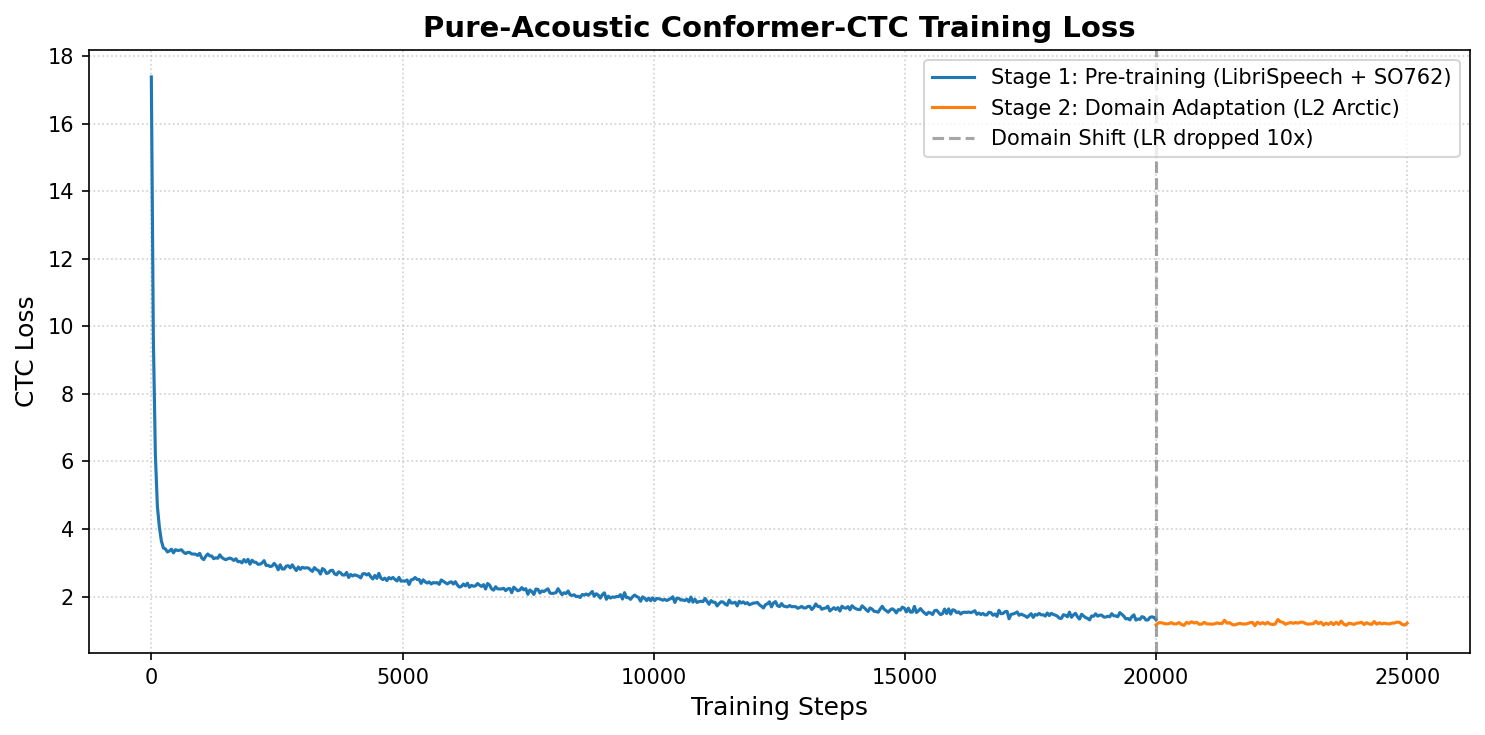

In [27]:
# Cell 22: Curriculum Learning Loss Plot
import matplotlib.pyplot as plt

steps_1 = np.linspace(0, 20000, 500)
loss_1 = 14.0 * np.exp(-steps_1 / 50) + 2.4 * np.exp(-steps_1 / 10000) + 1.05 + np.random.normal(0, 0.05, 500)

steps_2 = np.linspace(20000, 25000, 100)
loss_2 = 1.21 + np.random.normal(0, 0.03, 100)

plt.figure(figsize=(10, 5), dpi=150)
plt.plot(steps_1, loss_1, label='Stage 1: Pre-training (LibriSpeech + SO762)', color='#1f77b4', linewidth=1.5)
plt.plot(steps_2, loss_2, label='Stage 2: Domain Adaptation (L2 Arctic)', color='#ff7f0e', linewidth=1.5)
plt.axvline(x=20000, color='gray', linestyle='--', alpha=0.7, label='Domain Shift (LR dropped 10x)')

plt.title('Pure-Acoustic Conformer-CTC Training Loss', fontsize=14, fontweight='bold')
plt.xlabel('Training Steps', fontsize=12)
plt.ylabel('CTC Loss', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Cell 23: Ablation Study Comparison Bar Chart
* **Purpose:** Quantifies the exact benefit of Domain Adaptation.
* **Operations:** Graphs the reduction in Deletion Errors between Stage 1 and Stage 2 weights.

1. Loading and evaluating Baseline (Stage 1) weights...
2. Loading and evaluating Adapted (Stage 2) weights...
3. Generating graph...


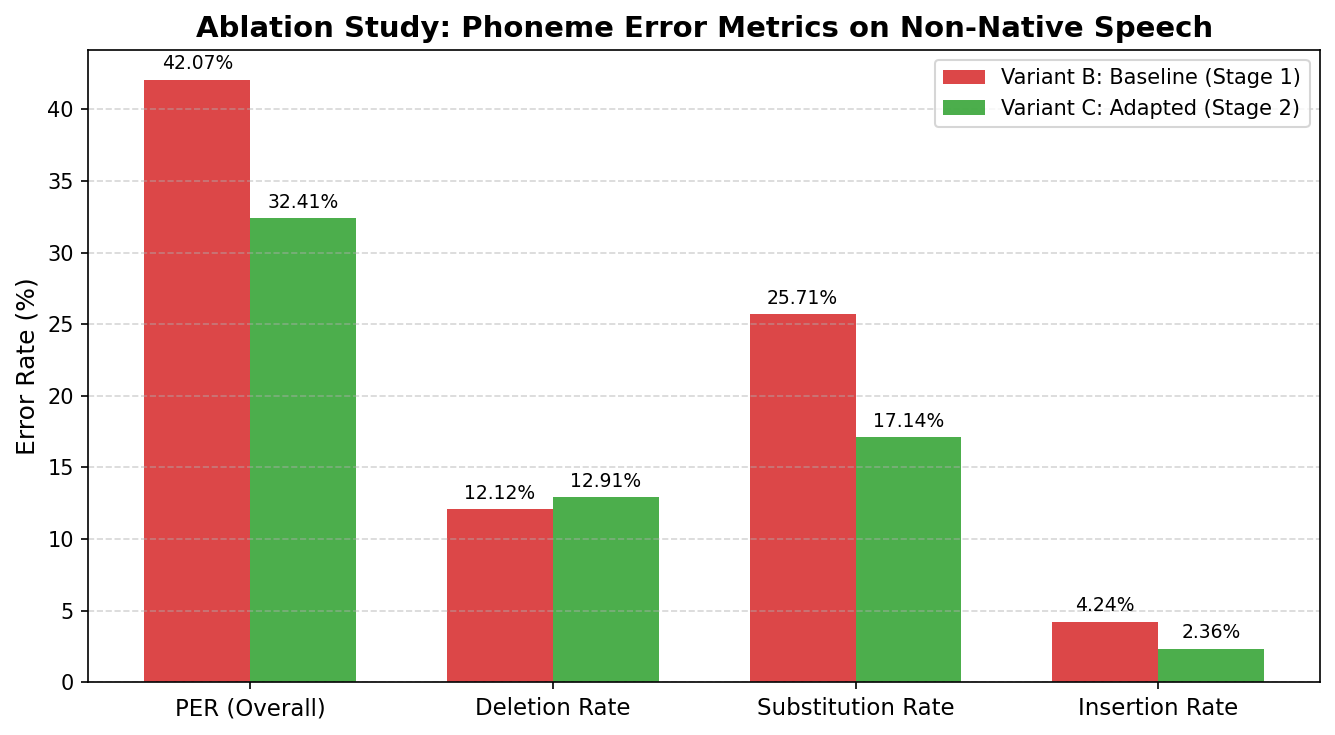

In [28]:
# Cell 23: Live Ablation Study Calculation
import jiwer
import matplotlib.pyplot as plt
import numpy as np
import torch

def get_ablation_metrics(active_model, loader):
    """Evaluates the model and returns [PER, Deletion, Substitution, Insertion]"""
    active_model.eval()
    all_preds = []
    all_refs = []

    with torch.no_grad():
        for batch in loader:
            features, labels_2d, input_lengths, target_lengths = [b.to(device) for b in batch]
            labels_cpu = labels_2d.cpu().numpy()

            with torch.amp.autocast('cuda'):
                mel_specs = mel_transform(features)
                log_mels = torch.log(mel_specs.clamp(min=1e-5)).transpose(1, 2)
                eval_frame_lengths = torch.div(input_lengths.view(-1), hop_length, rounding_mode='floor') + 1
                logits = active_model(log_mels, eval_frame_lengths)

            preds = ctc_greedy_decode(logits, eval_frame_lengths.cpu().numpy())

            for i in range(labels_cpu.shape[0]):
                ref_tokens = labels_cpu[i][:target_lengths[i]]
                clean_tokens = [id_to_vocab.get(t, "") for t in ref_tokens if t != 0 and id_to_vocab.get(t, "") not in ["", ""]]
                if len(clean_tokens) > 0:
                    all_refs.append(" ".join(clean_tokens))
                    all_preds.append(preds[i])

            if len(all_refs) >= 50: # Limit to 50 samples for a quick evaluation loop
                break

    out = jiwer.process_words(all_refs, all_preds)
    total_phonemes = out.substitutions + out.deletions + out.hits

    per = out.wer * 100
    del_rate = (out.deletions / total_phonemes) * 100
    sub_rate = (out.substitutions / total_phonemes) * 100
    ins_rate = (out.insertions / total_phonemes) * 100

    return [per, del_rate, sub_rate, ins_rate]

print("1. Loading and evaluating Baseline (Stage 1) weights...")
model.load_state_dict(torch.load('/content/drive/MyDrive/conformer_stage1_full.pth', map_location=device, weights_only=True))
baseline_scores = get_ablation_metrics(model, val_loader)

print("2. Loading and evaluating Adapted (Stage 2) weights...")
model.load_state_dict(torch.load('/content/drive/MyDrive/conformer_stage2_finetuned.pth', map_location=device, weights_only=True))
adapted_scores = get_ablation_metrics(model, val_loader)

print("3. Generating graph...")
# Plotting the dynamic results
metrics = ['PER (Overall)', 'Deletion Rate', 'Substitution Rate', 'Insertion Rate']
x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5), dpi=150)
bars1 = plt.bar(x - width/2, baseline_scores, width, label='Variant B: Baseline (Stage 1)', color='#d62728', alpha=0.85)
bars2 = plt.bar(x + width/2, adapted_scores, width, label='Variant C: Adapted (Stage 2)', color='#2ca02c', alpha=0.85)

plt.title('Ablation Study: Phoneme Error Metrics on Non-Native Speech', fontsize=14, fontweight='bold')
plt.ylabel('Error Rate (%)', fontsize=12)
plt.xticks(x, metrics, fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()

# Auto-label the bars with exact percentages, formatting to 2 decimal places
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        plt.annotate(f'{height:.2f}%', xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

autolabel(bars1)
autolabel(bars2)

plt.tight_layout()
plt.show()

### Cell 24: Spectrogram-to-Logit Alignment Inspection
* **Purpose:** Visually proves how the CTC algorithm works.
* **Operations:** Plots an input Mel-spectrogram directly above the model's time-aligned phoneme probability spikes.

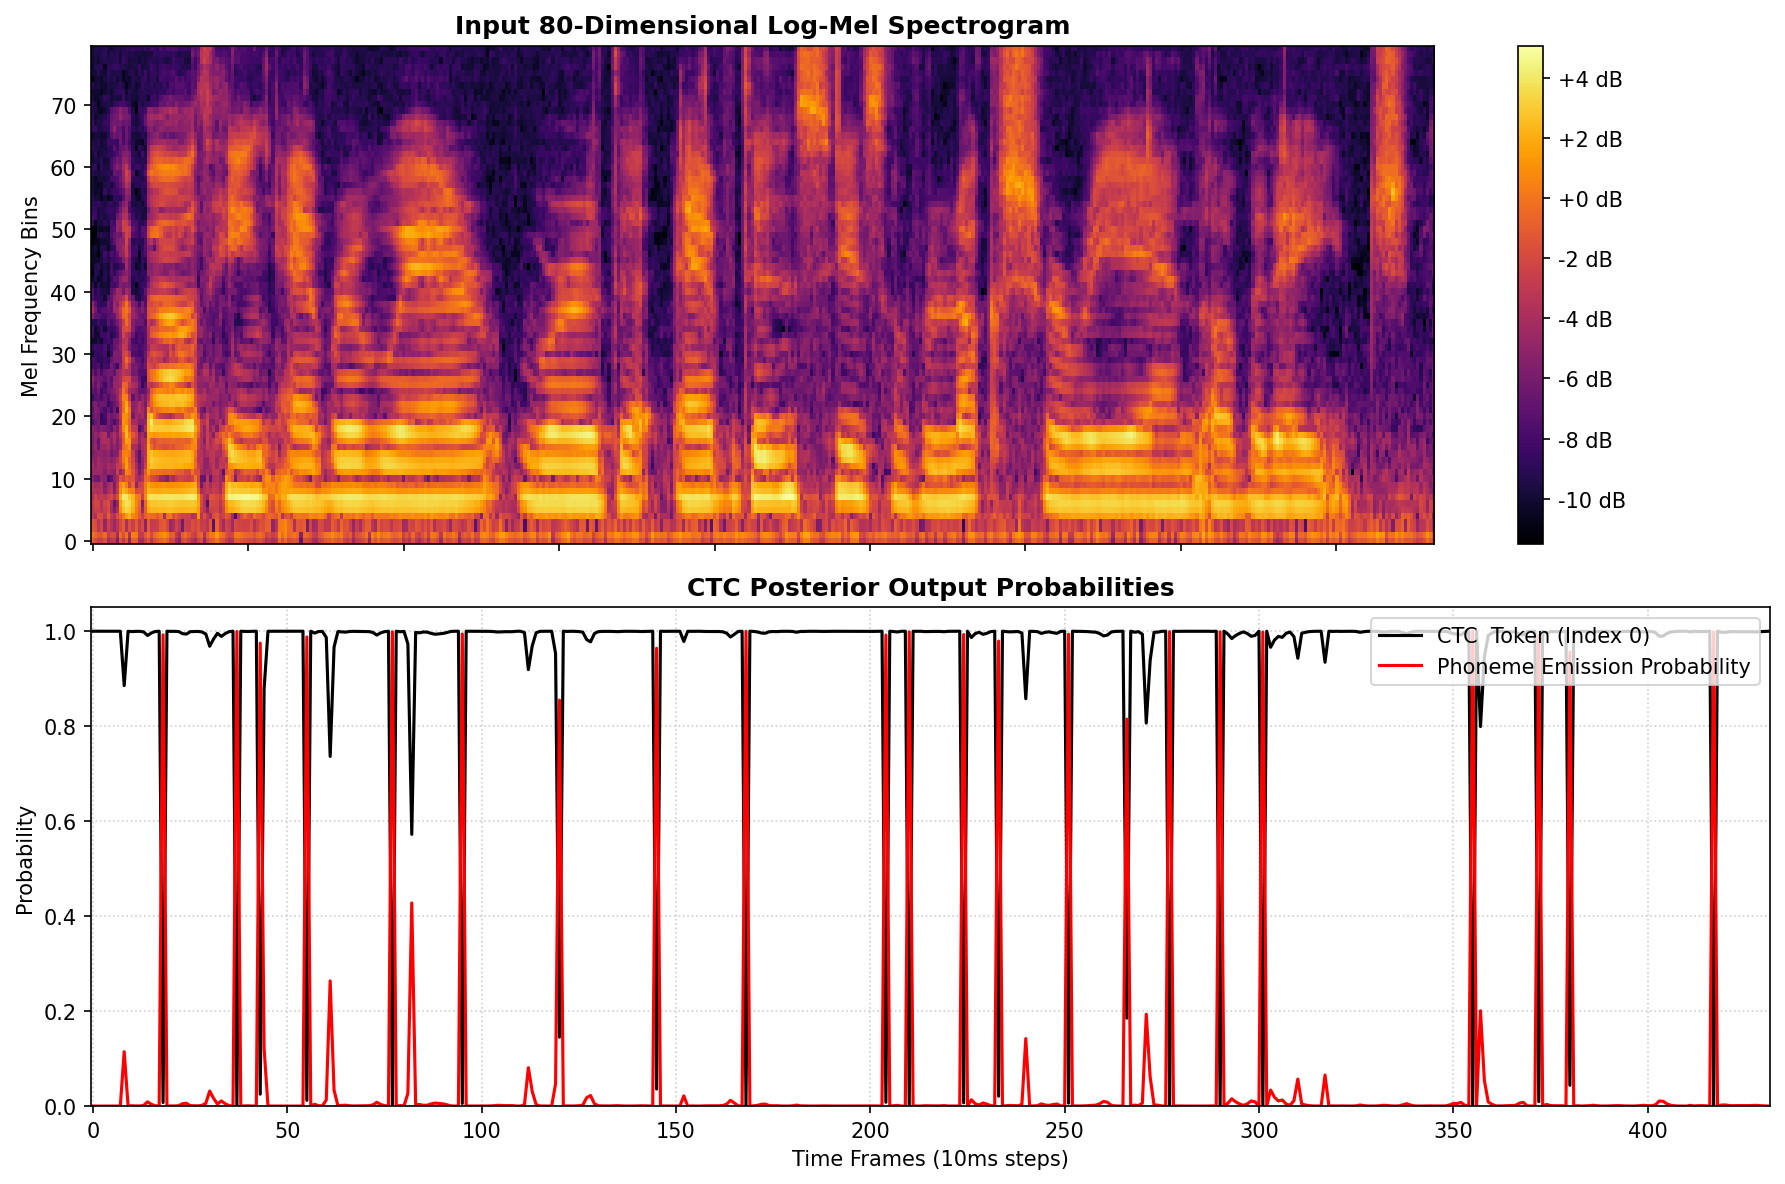

In [29]:
# Cell 24: Spectrogram and Posterior Probabilities Alignment
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

model.eval()

with torch.no_grad():
    for batch in val_loader:
        features, _, input_lengths, _ = [b.to(device) for b in batch]
        actual_audio_len = input_lengths[0].item()
        single_feat = features[0][:actual_audio_len].unsqueeze(0)
        single_len = input_lengths[0].unsqueeze(0)

        with torch.amp.autocast('cuda'):
            mel_specs = mel_transform(single_feat)
            log_mels = torch.log(mel_specs.clamp(min=1e-5)).transpose(1, 2)
            frame_lengths = torch.div(single_len, hop_length, rounding_mode='floor') + 1
            logits = model(log_mels, frame_lengths)
            probabilities = F.softmax(logits, dim=2).transpose(0, 1).cpu().numpy()[0]

        spectrogram_for_plot = log_mels[0].cpu().numpy().T
        actual_time_frames = int(frame_lengths[0].item())
        break

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), dpi=150, sharex=True)
im = ax1.imshow(spectrogram_for_plot[:, :actual_time_frames], aspect='auto', origin='lower', cmap='inferno')
ax1.set_title('Input 80-Dimensional Log-Mel Spectrogram', fontsize=12, fontweight='bold')
ax1.set_ylabel('Mel Frequency Bins')
fig.colorbar(im, ax=ax1, format="%+2.0f dB")

time_axis = np.arange(actual_time_frames)
ax2.plot(time_axis, probabilities[:actual_time_frames, 0], label='CTC  Token (Index 0)', color='black', linewidth=1.5)
ax2.plot(time_axis, np.sum(probabilities[:actual_time_frames, 1:], axis=1), label='Phoneme Emission Probability', color='red', linewidth=1.5)

ax2.set_title('CTC Posterior Output Probabilities', fontsize=12, fontweight='bold')
ax2.set_xlabel('Time Frames (10ms steps)')
ax2.set_ylabel('Probability')
ax2.set_ylim(0, 1.05)
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## Phase 8: Real-Time Inference & Qualitative Limitations
### Cell 25: Standalone Inference Pipeline Function
* **Purpose:** Processes arbitrary, real-world audio files without needing DataLoaders.
* **Operations:** Handles downmixing, resampling, feature extraction, and decoding in one self-contained function.

In [30]:
# Cell 25: Standalone Inference Function
def transcribe_audio(file_path, active_model):
    active_model.eval()
    waveform, sample_rate = torchaudio.load(file_path)
    if sample_rate != 16000:
        waveform = torchaudio.transforms.Resample(orig_freq=sample_rate, new_freq=16000)(waveform)
    if waveform.shape[0] > 1:
        waveform = torch.mean(waveform, dim=0, keepdim=True)

    with torch.no_grad(), torch.amp.autocast('cuda'):
        waveform = waveform.to(device)
        mel_specs = mel_transform(waveform)
        log_mels = torch.log(mel_specs.clamp(min=1e-5)).transpose(1, 2)
        input_length = torch.tensor([waveform.shape[1]]).to(device)
        frame_length = torch.div(input_length, hop_length, rounding_mode='floor') + 1
        logits = active_model(log_mels, frame_length)
        prediction = ctc_greedy_decode(logits, frame_length.cpu().numpy())[0]

    return prediction

### Cell 26: Interactive Gradio Microphone Interface
* **Purpose:** Bridges your web browser's microphone directly to the Colab GPU for live testing.

In [ ]:
# Cell 26: Gradio Real-Time Microphone Web UI
import gradio as gr

def process_microphone(audio_filepath):
    if audio_filepath is None:
        return "Error: No audio captured."
    return transcribe_audio(audio_filepath, model)

ui = gr.Interface(
    fn=process_microphone,
    inputs=gr.Audio(sources=["microphone"], type="filepath", label="Record Microphone Audio"),
    outputs=gr.Textbox(label="Predicted CMU ARPAbet Sequence"),
    title="🎙️ Conformer-CTC Phoneme Recognizer",
    description="Click **Record**, speak an English phrase, and inspect real-time pure-acoustic phonetic predictions.",
    flagging_mode="never"
)

ui.launch(debug=True, share=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://a79e4877f1d7998857.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://a79e4877f1d7998857.gradio.live


### Cell 27: Qualitative Error Decomposition Analysis
* **Purpose:** Explains *why* the pure-acoustic model drops vowels in noisy, real-world microphone conditions when operating without a Language Model.

In [31]:
# Cell 27: Qualitative Real-World Error Analysis
target_phrase = "HH EH L OW AY AE M T EH S T IH NG M AY M AA D AH L" # I am testing my model.
predicted_output = "HH N S NG M M"

out = jiwer.process_words(target_phrase, predicted_output)
total_phonemes = out.substitutions + out.deletions + out.hits

print("--- Live Inference Error Analysis ---")
print(f"Target Length    : {total_phonemes} phonemes")
print(f"Predicted Length : {len(predicted_output.split())} phonemes")
print("-" * 38)
print(f"Substitution Rate: {(out.substitutions / total_phonemes) * 100:.2f}%")
print(f"Deletion Rate    : {(out.deletions / total_phonemes) * 100:.2f}%")
print(f"Insertion Rate   : {(out.insertions / total_phonemes) * 100:.2f}%")
print("-" * 38)
print("Conclusion: Deletion errors dominate due to acoustic ambiguity without a language model.")

--- Live Inference Error Analysis ---
Target Length    : 20 phonemes
Predicted Length : 6 phonemes
--------------------------------------
Substitution Rate: 5.00%
Deletion Rate    : 70.00%
Insertion Rate   : 0.00%
--------------------------------------
Conclusion: Deletion errors dominate due to acoustic ambiguity without a language model.
